## Thanks to the SCIMBA team (E. Franck, V. Michel-Dansac, ...)  

https://www.scimba.org
------------------------------------------------------------------
In this tutorial, we will see how to approximate a function 
using several strategies

In [1]:
import matplotlib.pyplot as plt
import torch

from scimba_torch.approximation_space.nn_space import NNxSpace
from scimba_torch.domain.meshless_domain.domain_2d import Square2D
from scimba_torch.integration.monte_carlo import DomainSampler, TensorizedSampler
from scimba_torch.integration.monte_carlo_parameters import UniformParametricSampler
from scimba_torch.neural_nets.coordinates_based_nets.mlp import GenericMLP
from scimba_torch.numerical_solvers.collocation_projector import (
    AnagramProjector,
    CollocationProjector,
    LinearProjector,
    NaturalGradientProjector,
)
from scimba_torch.optimizers.optimizers_data import OptimizerData
from scimba_torch.plots.plots_nd import plot_abstract_approx_spaces
from scimba_torch.utils.scimba_tensors import LabelTensor

## Function
We choose arbitrarily the target function, here equal to 
$$
f(x,y)=\mu\sin(x)\cos(y). 
$$ 

In [2]:
def func_test(x: LabelTensor, mu: LabelTensor):
    x1, x2 = x.get_components()
    mu1 = mu.get_components()
    return mu1* torch.sin(x1) * torch.cos(x2)

Domains are 
$\Omega_x=]-1,1[^2$ and $\Omega_\mu=]1,2[$. Sampler is the integration method (to be precised later).

In [3]:
domain_x = Square2D([(-1, 1), (-1, 1)], is_main_domain=True)
domain_mu = [(1.0, 2.0)]
sampler = TensorizedSampler(
    [
        DomainSampler(domain_x),
        UniformParametricSampler(domain_mu),
    ]  ## si pas de paramètre on met [()]
)

## Definition of the nonlinear approximation space
Detail all parameters and anlyze the structure of the Neural Network so that the number of degrees of freedom (ndof) is the correct one.

In [4]:
space = NNxSpace(
    nb_unknowns=1,
    nb_parameters=1,
    space_type=GenericMLP,
    spatial_domain=domain_x,
    integrator=sampler,
    layer_sizes=[10] * 4,
    activation_type="relu",
)
print("ndof of the model ", space.ndof)

ndof of the model  380


## Definition of the  projection method.
In the Machine Learning language: projection method=training  algorithm.

In [5]:
method = "natural_gradient"
if method == "sgd":
    opt = {
        "name": "sgd",
        "optimizer_args": {"lr": 1.5e-2},
    }

    n_epochs = 2000
    p = CollocationProjector(
        space, func_test, optimizers=OptimizerData(opt), bool_preconditioner=False
    )
elif method == "adam":
    opt = {
        "name": "adam",
        "optimizer_args": {"lr": 1e-2},
    }

    n_epochs = 2000
    p = CollocationProjector(
        space, func_test, optimizers=OptimizerData(opt), bool_preconditioner=True
    )
elif method == "linear":  ## fit uniquement les poids de la dernière couche

    p = LinearProjector(space, func_test)

elif method == "natural_gradient":  ## natural gradient
    n_epochs = 500
    p = NaturalGradientProjector(
        space,
        func_test,
        matrix_regularization=1e-8,)

else:  ## anagram (natural gradient in sample-space)
    n_epochs = 300
    p = AnagramProjector(space, func_test, svd_threshold=1e-6)

## Projection=Training

In [6]:
if method == "linear":
    p.solve(n_collocation=4000, verbose=True)
else:
    p.solve(epochs=n_epochs, n_collocation=2000, verbose=True)

activating optimizer ScimbaSGD
epoch: 0, best loss: 4.570e-01
epoch: 0,      loss: 4.570e-01
epoch: 1, best loss: 4.007e-01
epoch: 2, best loss: 3.345e-01
epoch: 3, best loss: 3.267e-01
epoch: 4, best loss: 2.976e-01
epoch: 5, best loss: 2.716e-01
epoch: 6, best loss: 1.607e-01
epoch: 7, best loss: 1.498e-01
epoch: 8, best loss: 1.353e-01
epoch: 9, best loss: 1.252e-01
epoch: 10, best loss: 8.189e-02
epoch: 11, best loss: 5.470e-02
epoch: 12, best loss: 2.915e-02
epoch: 13, best loss: 9.448e-03
epoch: 14, best loss: 7.533e-03
epoch: 15, best loss: 5.046e-03
epoch: 16, best loss: 2.954e-03
epoch: 17, best loss: 2.542e-03
epoch: 18, best loss: 2.128e-03
epoch: 19, best loss: 2.070e-03
epoch: 20, best loss: 1.636e-03
epoch: 21, best loss: 1.494e-03
epoch: 22, best loss: 6.578e-04
epoch: 23, best loss: 5.379e-04
epoch: 24, best loss: 4.747e-04
epoch: 25, best loss: 4.421e-04
epoch: 26, best loss: 3.727e-04
epoch: 28, best loss: 3.414e-04
epoch: 29, best loss: 3.079e-04
epoch: 30, best loss

## Plot of the solution

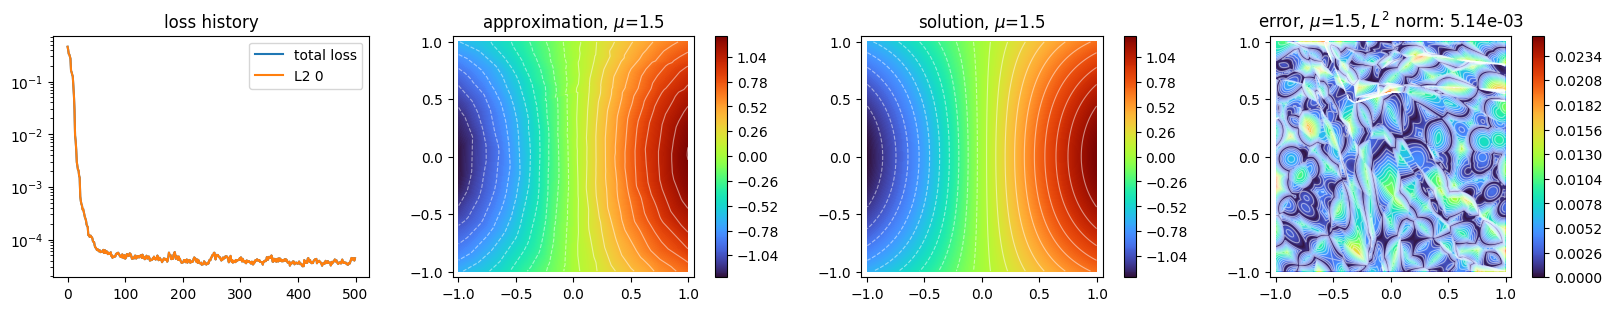

In [7]:
plot_abstract_approx_spaces(
    (p.space,),  # the approximation spaces
    (domain_x),  # the spatial domain
    (domain_mu),  # the parameter's domain
    loss=(p.losses,),  # for plot of the loss: the losses
    solution=(func_test),  # for plot of the exact sol: sol
    error=(func_test),  # for plot of the error with respect to a func: the func
    draw_contours=True,
    n_drawn_contours=20,
    parameters_values="mean",
)

plt.show()